In [1]:
from pathlib import Path
import sys
import random
import numpy as np
import torch
import segmentation_models_pytorch as smp

# 1. Lokasi project
PROJECT_DIR = Path(
    "/Users/salman/Projects/AI/WoundVision-AI"
)

DATA_ROOT = PROJECT_DIR / "data" / "LUTSeg"

# 2. Starting checkpoint V5
START_CHECKPOINT = (
    PROJECT_DIR
    / "runs"
    / "notebook_v4a_mps"
    / "best_model.pth"
)

# 3. Konfigurasi eksperimen
SEED = 42
BATCH_SIZE = 2
EPOCHS = 3
LEARNING_RATE = 1e-4

# 4. Reproducibility
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# 5. Pilih perangkat komputasi
device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

# 6. Tambahkan source code project
src_path = str(PROJECT_DIR / "src")

if src_path not in sys.path:
    sys.path.insert(0, src_path)

# 7. Verifikasi
print("=== WOUNDVISION AI V5 ===")
print("PyTorch:", torch.__version__)
print("Device:", device)
print("Dataset found:", DATA_ROOT.exists())
print("Checkpoint found:", START_CHECKPOINT.exists())

/Users/salman/Projects/AI/WoundVision-AI/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


=== WOUNDVISION AI V5 ===
PyTorch: 2.15.0
Device: mps
Dataset found: True
Checkpoint found: True


In [2]:
%pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 2.5 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ipywidgets]

[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [3]:
from woundvision.data import WoundDataset

# Dataset training
train_dataset = WoundDataset(
    root_dir=DATA_ROOT,
    split_file="train.txt",
    image_size=320
)

# Dataset validation
val_dataset = WoundDataset(
    root_dir=DATA_ROOT,
    split_file="val.txt",
    image_size=320
)

# Ambil satu sampel
image, mask = train_dataset[0]

print("=== DATASET V5 ===")
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Image shape:", image.shape)
print("Mask shape:", mask.shape)
print("Image range:", image.min().item(), image.max().item())
print("Mask classes:", torch.unique(mask).tolist())

=== DATASET V5 ===
Training images: 111
Validation images: 30
Image shape: torch.Size([3, 320, 320])
Mask shape: torch.Size([320, 320])
Image range: 0.0 1.0
Mask classes: [0, 1, 2, 3, 4]


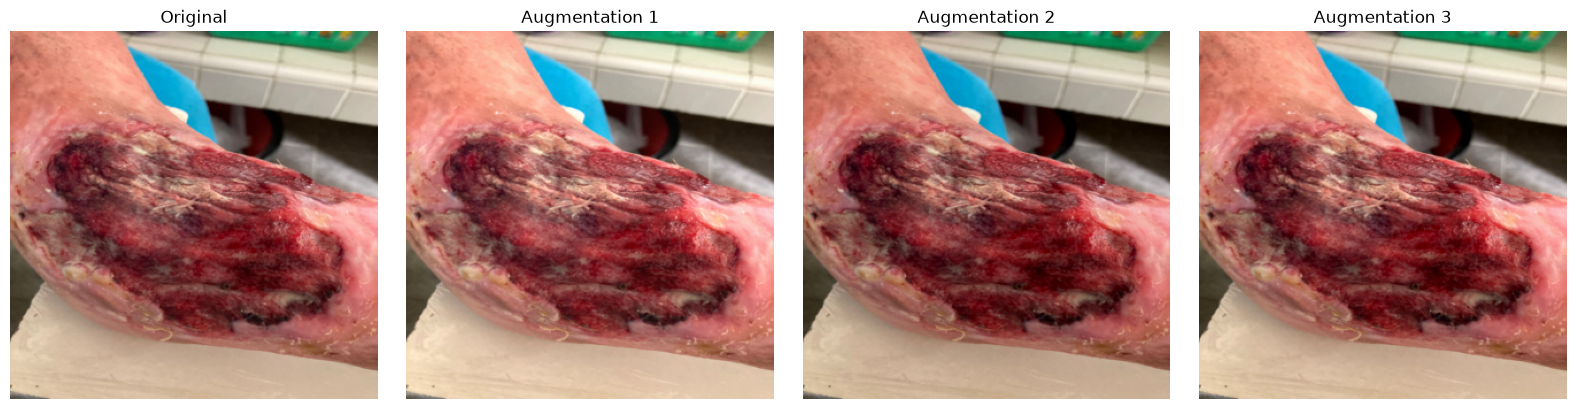

In [4]:
import matplotlib.pyplot as plt
from torchvision.transforms import ColorJitter

# 1. Definisikan augmentasi
color_augment = ColorJitter(
    brightness=0.10,
    contrast=0.10,
    saturation=0.05,
    hue=0
)

# 2. Ambil gambar training
image, mask = train_dataset[0]

# 3. Buat tiga variasi augmentasi
augmented_images = [
    color_augment(image)
    for _ in range(3)
]

# 4. Gabungkan gambar asli dan augmentasi
images = [image] + augmented_images

titles = [
    "Original",
    "Augmentation 1",
    "Augmentation 2",
    "Augmentation 3"
]

# 5. Visualisasikan
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for ax, img, title in zip(axes, images, titles):

    img_np = img.permute(1, 2, 0).numpy()

    ax.imshow(img_np)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [5]:
from torch.utils.data import Dataset

class AugmentedWoundDataset(Dataset):

    def __init__(self, base_dataset, transform):
        self.base_dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.base_dataset)

    def __getitem__(self, idx):

        # Ambil gambar dan mask
        image, mask = self.base_dataset[idx]

        # Augmentasi hanya gambar RGB
        image = self.transform(image)

        # Mask tidak berubah
        return image, mask


# Buat augmented training dataset
train_dataset_aug = AugmentedWoundDataset(
    base_dataset=train_dataset,
    transform=color_augment
)

# Ambil sampel untuk verifikasi
original_image, original_mask = train_dataset[0]
aug_image, aug_mask = train_dataset_aug[0]

print("=== AUGMENTED DATASET CHECK ===")
print("Total images:", len(train_dataset_aug))
print("Image shape:", aug_image.shape)
print("Mask shape:", aug_mask.shape)
print("Mask unchanged:", torch.equal(original_mask, aug_mask))
print("Image range:", aug_image.min().item(), aug_image.max().item())

=== AUGMENTED DATASET CHECK ===
Total images: 111
Image shape: torch.Size([3, 320, 320])
Mask shape: torch.Size([320, 320])
Mask unchanged: True
Image range: 0.02016543224453926 0.968298614025116


In [6]:
from torch.utils.data import DataLoader

# Konfigurasi DataLoader
BATCH_SIZE = 2
SEED = 42

# 1. DataLoader tanpa augmentasi
train_loader_control = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)

# 2. DataLoader dengan augmentasi
train_loader_aug = DataLoader(
    train_dataset_aug,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)

# 3. Validation DataLoader
val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("=== V5 DATALOADER CHECK ===")

print("Control batches:", len(train_loader_control))
print("Augmented batches:", len(train_loader_aug))
print("Validation batches:", len(val_loader))

print("Control images:", len(train_loader_control.dataset))
print("Augmented images:", len(train_loader_aug.dataset))
print("Validation images:", len(val_loader.dataset))

=== V5 DATALOADER CHECK ===
Control batches: 56
Augmented batches: 56
Validation batches: 15
Control images: 111
Augmented images: 111
Validation images: 30


In [7]:
# === V5 MODEL INITIALIZATION ===

# 1. Load checkpoint V4-A
checkpoint_v4 = torch.load(
    START_CHECKPOINT,
    map_location="cpu",
    weights_only=True
)

# 2. Fungsi untuk membuat model dan optimizer
def create_v5_model():

    model = smp.Unet(
        encoder_name="resnet34",
        encoder_weights=None,
        in_channels=3,
        classes=6,
        activation=None
    )

    # Gunakan bobot checkpoint yang sama
    model.load_state_dict(
        checkpoint_v4["model_state"],
        strict=True
    )

    model = model.to(device)

    # Optimizer baru
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE,
        weight_decay=1e-4
    )

    return model, optimizer


# 3. Buat dua model independen
model_control, optimizer_control = create_v5_model()

model_aug, optimizer_aug = create_v5_model()


# 4. Pastikan bobot awal keduanya identik
same_weights = all(
    torch.equal(
        model_control.state_dict()[key],
        model_aug.state_dict()[key]
    )
    for key in model_control.state_dict()
)

print("=== V5 MODEL INITIALIZATION ===")
print("Starting epoch:", checkpoint_v4["epoch"])
print("Starting Dice:", checkpoint_v4["clinical_3_dice"])
print("Device:", device)
print("Control optimizer:", type(optimizer_control).__name__)
print("Augmented optimizer:", type(optimizer_aug).__name__)
print("Identical starting weights:", same_weights)

=== V5 MODEL INITIALIZATION ===
Starting epoch: 3
Starting Dice: 0.5668246150016785
Device: mps
Control optimizer: AdamW
Augmented optimizer: AdamW
Identical starting weights: True


In [8]:
import json
import torch.nn as nn

from woundvision.evaluate import (
    evaluate_model,
    calculate_metrics,
    MEAN,
    STD
)

# 1. Baca konfigurasi training V3
config_path = (
    PROJECT_DIR / "runs"
    / "20261121_185427_e291f3"
    / "config.json"
)

with open(config_path, "r") as f:
    config_v3 = json.load(f)

# 2. Class weights yang sama dengan V4-A
class_weights = torch.tensor(
    config_v3["class_weights"],
    dtype=torch.float32,
    device=device
)

# 3. Weighted Cross Entropy
ce_loss = nn.CrossEntropyLoss(
    weight=class_weights,
    ignore_index=255
)

# 4. Multiclass Dice Loss
dice_loss = smp.losses.DiceLoss(
    mode="multiclass",
    from_logits=True,
    ignore_index=255
)

# 5. Normalisasi sesuai training sebelumnya
mean = torch.tensor(
    MEAN, device=device
).view(1, 3, 1, 1)

std = torch.tensor(
    STD, device=device
).view(1, 3, 1, 1)

# 6. Verifikasi model sebelum training
cm = evaluate_model(
    model_control,
    val_loader,
    device
)

metrics = calculate_metrics(cm)
dice = metrics["dice_per_class"]

clinical_dice = sum(
    float(dice[i]) for i in [2, 3, 4]
) / 3

print("=== V5 TRAINING CONFIGURATION ===")
print("Loss: Weighted CE + Dice")
print("Class weights:", class_weights.tolist())
print("Device:", device)

print("\n=== STARTING BASELINE ===")
print(f"Slough Dice      : {float(dice[2]):.4f}")
print(f"Granulation Dice : {float(dice[3]):.4f}")
print(f"Necrotic Dice    : {float(dice[4]):.4f}")
print(f"Clinical-3 Dice  : {clinical_dice:.4f}")

=== V5 TRAINING CONFIGURATION ===
Loss: Weighted CE + Dice
Class weights: [0.25, 1.0, 1.3411999940872192, 1.0134999752044678, 6.0, 1.0]
Device: mps

=== STARTING BASELINE ===
Slough Dice      : 0.3670
Granulation Dice : 0.7494
Necrotic Dice    : 0.5841
Clinical-3 Dice  : 0.5668


In [9]:
import json
import shutil

def run_v5_experiment(name, model, optimizer, train_loader):

    # 1. Siapkan folder hasil eksperimen
    run_dir = PROJECT_DIR / "runs" / name

    if run_dir.exists() and any(run_dir.iterdir()):
        raise FileExistsError(f"Run sudah ada: {run_dir}")

    run_dir.mkdir(parents=True, exist_ok=True)

    # 2. Tetapkan seed dan baseline
    torch.manual_seed(SEED)

    best_dice = float(checkpoint_v4["clinical_3_dice"])
    best_epoch = 0
    history = []

    # Simpan baseline sebagai kandidat terbaik awal
    shutil.copy2(
        START_CHECKPOINT,
        run_dir / "best_model.pth"
    )

    # 3. Training beberapa epoch
    for epoch in range(1, EPOCHS + 1):

        model.train()
        total_loss = 0.0
        total_images = 0

        for images, masks in train_loader:

            images = images.to(device)
            masks = masks.to(device)

            # Normalisasi sesuai pipeline asli
            images = (images - mean) / std

            optimizer.zero_grad(set_to_none=True)

            outputs = model(images)

            loss = (
                ce_loss(outputs, masks)
                + dice_loss(outputs, masks)
            )

            if not torch.isfinite(loss).item():
                raise RuntimeError("Non-finite training loss")

            loss.backward()
            optimizer.step()

            batch_size = images.size(0)
            total_loss += loss.item() * batch_size
            total_images += batch_size

        train_loss = total_loss / total_images

        # 4. Evaluasi validation set
        cm = evaluate_model(model, val_loader, device)
        metrics = calculate_metrics(cm)

        dice = metrics["dice_per_class"]

        clinical_dice = sum(
            float(dice[i]) for i in [2, 3, 4]
        ) / 3

        # 5. Catat metrik
        record = {
            "epoch": epoch,
            "train_loss": float(train_loss),
            "slough_dice": float(dice[2]),
            "granulation_dice": float(dice[3]),
            "necrotic_dice": float(dice[4]),
            "clinical_3_dice": float(clinical_dice)
        }

        history.append(record)

        # 6. Simpan checkpoint setiap epoch
        checkpoint_data = {
            **record,
            "model_state": {
                k: v.detach().cpu()
                for k, v in model.state_dict().items()
            },
            "optimizer_state": optimizer.state_dict(),
            "starting_checkpoint": str(START_CHECKPOINT)
        }

        epoch_path = run_dir / f"epoch_{epoch:02d}.pth"
        torch.save(checkpoint_data, epoch_path)

        # 7. Update checkpoint terbaik
        if clinical_dice > best_dice:
            best_dice = clinical_dice
            best_epoch = epoch

            shutil.copy2(
                epoch_path,
                run_dir / "best_model.pth"
            )

        # 8. Simpan log
        with open(run_dir / "metrics.json", "w") as f:
            json.dump(history, f, indent=2)

        print(f"\n=== {name} | EPOCH {epoch} ===")
        print(f"Train Loss    : {train_loss:.4f}")
        print(f"Slough        : {float(dice[2]):.4f}")
        print(f"Granulation   : {float(dice[3]):.4f}")
        print(f"Necrotic      : {float(dice[4]):.4f}")
        print(f"Clinical-3    : {clinical_dice:.4f}")

    print(f"\nBEST EPOCH: {best_epoch} (0 = V4-A baseline)")
    print(f"BEST CLINICAL-3 DICE: {best_dice:.4f}")

    return history

In [10]:
# Pastikan bobot awal kedua model masih identik
assert all(
    torch.equal(
        model_control.state_dict()[k],
        model_aug.state_dict()[k]
    )
    for k in model_control.state_dict()
)

# Eksperimen tanpa augmentasi
history_control = run_v5_experiment(
    "notebook_v5_control",
    model_control,
    optimizer_control,
    train_loader_control
)

# Eksperimen dengan ColorJitter
history_aug = run_v5_experiment(
    "notebook_v5_augmented",
    model_aug,
    optimizer_aug,
    train_loader_aug
)


=== notebook_v5_control | EPOCH 1 ===
Train Loss    : 0.5701
Slough        : 0.3123
Granulation   : 0.7056
Necrotic      : 0.4652
Clinical-3    : 0.4944

=== notebook_v5_control | EPOCH 2 ===
Train Loss    : 0.5364
Slough        : 0.3750
Granulation   : 0.6831
Necrotic      : 0.5739
Clinical-3    : 0.5440

=== notebook_v5_control | EPOCH 3 ===
Train Loss    : 0.4843
Slough        : 0.4220
Granulation   : 0.7228
Necrotic      : 0.5255
Clinical-3    : 0.5568

BEST EPOCH: 0 (0 = V4-A baseline)
BEST CLINICAL-3 DICE: 0.5668

=== notebook_v5_augmented | EPOCH 1 ===
Train Loss    : 0.5699
Slough        : 0.3166
Granulation   : 0.6958
Necrotic      : 0.4674
Clinical-3    : 0.4933

=== notebook_v5_augmented | EPOCH 2 ===
Train Loss    : 0.5334
Slough        : 0.4057
Granulation   : 0.6287
Necrotic      : 0.4806
Clinical-3    : 0.5050

=== notebook_v5_augmented | EPOCH 3 ===
Train Loss    : 0.4923
Slough        : 0.4254
Granulation   : 0.7489
Necrotic      : 0.6091
Clinical-3    : 0.5945

BEST 

In [11]:
import json
import pandas as pd

experiments = {
    "V5-Control": "notebook_v5_control",
    "V5-Augmented": "notebook_v5_augmented"
}

records = []

for name, folder in experiments.items():

    metrics_path = (
        PROJECT_DIR / "runs" / folder / "metrics.json"
    )

    with open(metrics_path) as f:
        history = json.load(f)

    for epoch in history:
        records.append({
            "Model": name,
            "Epoch": epoch["epoch"],
            "Slough": epoch["slough_dice"],
            "Granulation": epoch["granulation_dice"],
            "Necrotic": epoch["necrotic_dice"],
            "Clinical-3": epoch["clinical_3_dice"]
        })

df_v5 = pd.DataFrame(records)

display(df_v5.round(4))

,Model,Epoch,Slough,Granulation,Necrotic,Clinical-3
0,V5-Control,1,0.3123,0.7056,0.4652,0.4944
1,V5-Control,2,0.3750,0.6831,0.5739,0.5440
2,V5-Control,3,0.4220,0.7228,0.5255,0.5568
3,V5-Augmented,1,0.3166,0.6958,0.4674,0.4933
4,V5-Augmented,2,0.4057,0.6287,0.4806,0.5050
5,V5-Augmented,3,0.4254,0.7489,0.6091,0.5945


In [12]:
# === VERIFY V5 BEST CHECKPOINT ===

best_path = (
    PROJECT_DIR
    / "runs"
    / "notebook_v5_augmented"
    / "best_model.pth"
)

# 1. Load checkpoint
best_ckpt = torch.load(
    best_path,
    map_location="cpu",
    weights_only=True
)

# 2. Bangun model baru
best_model = smp.Unet(
    encoder_name="resnet34",
    encoder_weights=None,
    in_channels=3,
    classes=6,
    activation=None
).to(device)

# 3. Load bobot
best_model.load_state_dict(
    best_ckpt["model_state"],
    strict=True
)

best_model.eval()

# 4. Evaluasi ulang
cm_best = evaluate_model(
    best_model,
    val_loader,
    device
)

best_metrics = calculate_metrics(cm_best)
best_dice = best_metrics["dice_per_class"]

clinical_dice = sum(
    float(best_dice[i])
    for i in [2, 3, 4]
) / 3

# 5. Tampilkan hasil
print("=== V5 BEST MODEL VERIFICATION ===")
print("Saved epoch:", best_ckpt["epoch"])
print("Saved Dice:", best_ckpt["clinical_3_dice"])
print("Recomputed Dice:", round(clinical_dice, 4))

print("\nPER-CLASS DICE")
print("Slough:", round(float(best_dice[2]), 4))
print("Granulation:", round(float(best_dice[3]), 4))
print("Necrotic:", round(float(best_dice[4]), 4))

print("\nCheckpoint verified:", abs(
    clinical_dice - best_ckpt["clinical_3_dice"]
) < 1e-4)

=== V5 BEST MODEL VERIFICATION ===
Saved epoch: 3
Saved Dice: 0.5944744944572449
Recomputed Dice: 0.5945

PER-CLASS DICE
Slough: 0.4254
Granulation: 0.7489
Necrotic: 0.6091

Checkpoint verified: True


In [13]:
import pandas as pd

# Confusion matrix V5
cm = cm_best.cpu().numpy()

class_names = {
    2: "Slough",
    3: "Granulation",
    4: "Necrotic"
}

results = []

for class_id, name in class_names.items():

    # True Positive
    tp = cm[class_id, class_id]

    # False Positive
    fp = cm[:, class_id].sum() - tp

    # False Negative
    fn = cm[class_id, :].sum() - tp

    # Precision
    precision = tp / (tp + fp) if tp + fp > 0 else 0

    # Recall
    recall = tp / (tp + fn) if tp + fn > 0 else 0

    # Dice
    dice = (
        2 * tp / (2 * tp + fp + fn)
        if 2 * tp + fp + fn > 0 else 0
    )

    results.append({
        "Tissue": name,
        "Precision": round(precision, 4),
        "Recall": round(recall, 4),
        "Dice": round(dice, 4),
        "FP Pixels": int(fp),
        "FN Pixels": int(fn)
    })

df_metrics_v5 = pd.DataFrame(results)

display(df_metrics_v5)

,Tissue,Precision,Recall,Dice,FP Pixels,FN Pixels
0,Slough,0.5236,0.3582,0.4254,16235,31974
1,Granulation,0.7882,0.7133,0.7489,42524,63601
2,Necrotic,0.6898,0.5453,0.6091,11502,21329


In [14]:
# Ambil confusion matrix V5
cm = cm_best.cpu().numpy()

class_names = [
    "Background",
    "Epithelial",
    "Slough",
    "Granulation",
    "Necrotic",
    "Other"
]

slough_id = 2

# Semua piksel Ground Truth Slough
total_slough = cm[slough_id, :].sum()

print("=== WHERE DOES TRUE SLOUGH GO? ===")

for class_id, name in enumerate(class_names):

    pixels = cm[slough_id, class_id]

    percentage = pixels / total_slough * 100

    print(
        f"{name:12s} | "
        f"{pixels:6d} pixels | "
        f"{percentage:.2f}%"
    )

print("\n=== FALSE POSITIVE SLOUGH SOURCES ===")

# Semua prediksi Slough
total_pred_slough = cm[:, slough_id].sum()

for class_id, name in enumerate(class_names):

    pixels = cm[class_id, slough_id]

    percentage = pixels / total_pred_slough * 100

    print(
        f"{name:12s} | "
        f"{pixels:6d} pixels | "
        f"{percentage:.2f}%"
    )

=== WHERE DOES TRUE SLOUGH GO? ===
Background   |   5399 pixels | 10.84%
Epithelial   |  12514 pixels | 25.12%
Slough       |  17844 pixels | 35.82%
Granulation  |  13310 pixels | 26.72%
Necrotic     |    751 pixels | 1.51%
Other        |      0 pixels | 0.00%

=== FALSE POSITIVE SLOUGH SOURCES ===
Background   |   2069 pixels | 6.07%
Epithelial   |   5516 pixels | 16.19%
Slough       |  17844 pixels | 52.36%
Granulation  |   7681 pixels | 22.54%
Necrotic     |    860 pixels | 2.52%
Other        |    109 pixels | 0.32%


In [15]:
slough_errors = []

best_model.eval()

with torch.inference_mode():
    for idx in range(len(val_dataset)):

        image_i, mask_i = val_dataset[idx]

        # Normalisasi sesuai pipeline V5
        x = image_i.unsqueeze(0).to(device)
        x = (x - mean) / std

        # Prediksi model
        pred = best_model(x).argmax(dim=1).squeeze(0).cpu()

        # Piksel Ground Truth Slough
        gt_slough = mask_i == 2
        total = gt_slough.sum().item()

        if total < 500:
            continue

        # Kesalahan Slough menjadi kelas lain
        to_epithelial = (gt_slough & (pred == 1)).sum().item()
        to_granulation = (gt_slough & (pred == 3)).sum().item()

        confusion_rate = (
            (to_epithelial + to_granulation) / total
        )

        slough_errors.append({
            "Image": idx,
            "GT Slough": total,
            "To Epithelial": to_epithelial,
            "To Granulation": to_granulation,
            "Confusion Rate": confusion_rate
        })

# Urutkan berdasarkan kesalahan tertinggi
slough_errors.sort(
    key=lambda x: x["Confusion Rate"],
    reverse=True
)

print("=== HARDEST SLOUGH IMAGES ===")

for item in slough_errors[:5]:
    print(item)

=== HARDEST SLOUGH IMAGES ===
{'Image': 16, 'GT Slough': 1106, 'To Epithelial': 15, 'To Granulation': 1091, 'Confusion Rate': 1.0}
{'Image': 15, 'GT Slough': 1719, 'To Epithelial': 175, 'To Granulation': 1526, 'Confusion Rate': 0.9895287958115183}
{'Image': 13, 'GT Slough': 834, 'To Epithelial': 0, 'To Granulation': 761, 'Confusion Rate': 0.9124700239808153}
{'Image': 11, 'GT Slough': 3353, 'To Epithelial': 420, 'To Granulation': 2161, 'Confusion Rate': 0.7697584252907844}
{'Image': 26, 'GT Slough': 1571, 'To Epithelial': 638, 'To Granulation': 493, 'Confusion Rate': 0.7199236155315086}


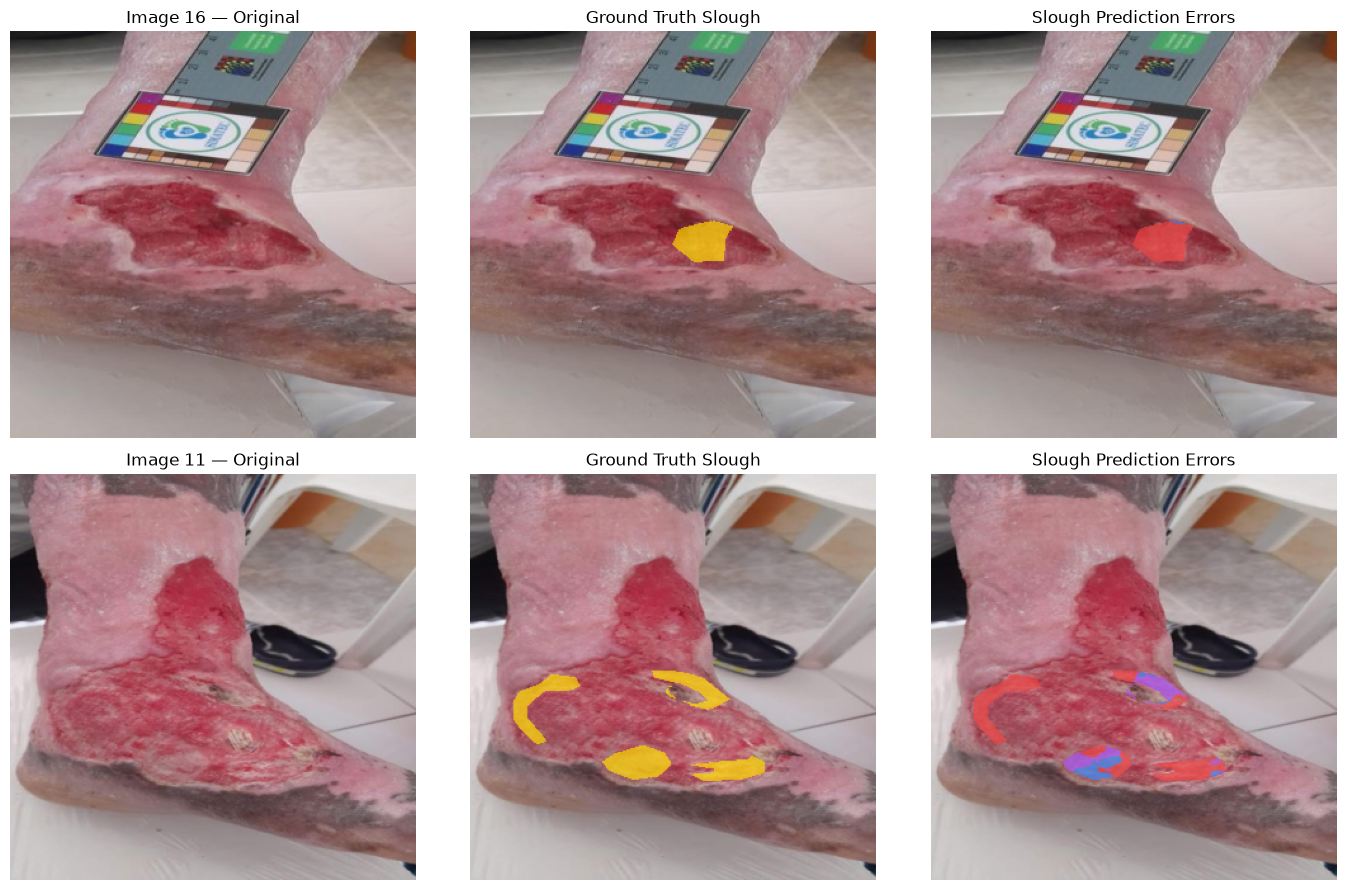

In [16]:
from matplotlib.patches import Patch

sample_indices = [16, 11]

fig, axes = plt.subplots(2, 3, figsize=(14, 9))

best_model.eval()

for row, idx in enumerate(sample_indices):

    image_i, mask_i = val_dataset[idx]

    x = image_i.unsqueeze(0).to(device)
    x = (x - mean) / std

    with torch.inference_mode():
        pred = best_model(x).argmax(dim=1)

    img = image_i.permute(1, 2, 0).cpu().numpy()
    gt = mask_i.cpu().numpy()
    pred = pred.squeeze(0).cpu().numpy()

    gt_slough = gt == 2

    # Piksel Slough berdasarkan hasil prediksi
    correct = gt_slough & (pred == 2)
    to_granulation = gt_slough & (pred == 3)
    to_epithelial = gt_slough & (pred == 1)
    other_error = gt_slough & ~(
        (pred == 2) | (pred == 3) | (pred == 1)
    )

    # Overlay RGBA
    overlay = np.zeros((*gt.shape, 4), dtype=float)

    overlay[correct] = [0.13, 0.77, 0.37, 0.7]
    overlay[to_granulation] = [0.94, 0.27, 0.27, 0.7]
    overlay[to_epithelial] = [0.23, 0.51, 0.96, 0.7]
    overlay[other_error] = [0.66, 0.33, 0.97, 0.7]

    # Original
    axes[row, 0].imshow(img)
    axes[row, 0].set_title(f"Image {idx} — Original")

    # Ground Truth Slough
    axes[row, 1].imshow(img)
    gt_overlay = np.zeros((*gt.shape, 4))
    gt_overlay[gt_slough] = [1, 0.85, 0, 0.7]
    axes[row, 1].imshow(gt_overlay)
    axes[row, 1].set_title("Ground Truth Slough")

    # Error overlay
    axes[row, 2].imshow(img)
    axes[row, 2].imshow(overlay)
    axes[row, 2].set_title("Slough Prediction Errors")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

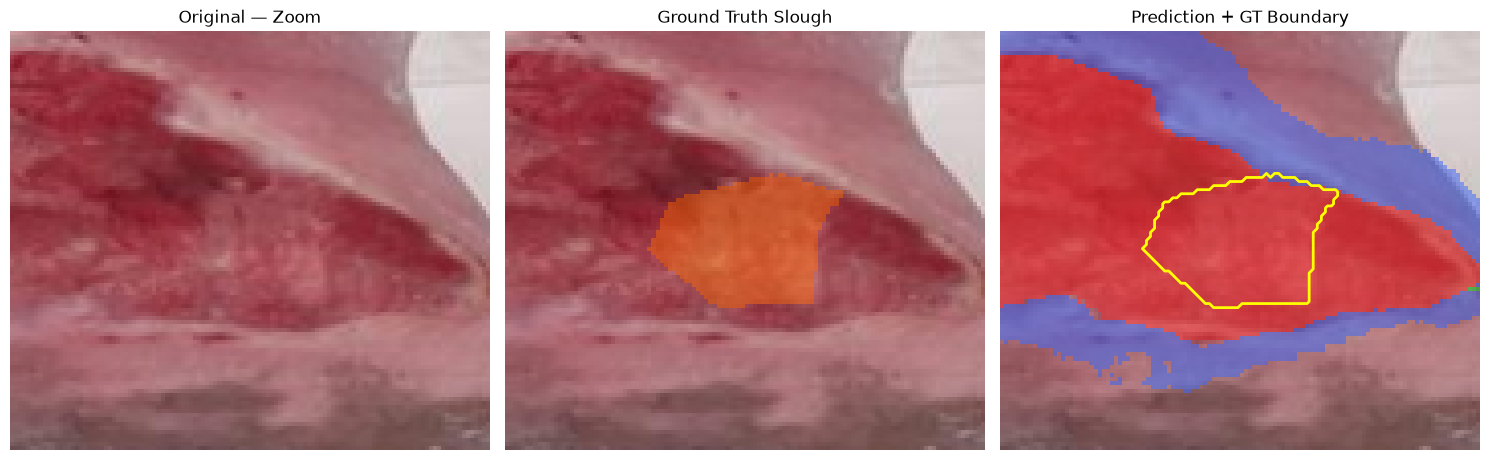

In [17]:
# === STEP 16: ZOOM SLOUGH ERROR ===

idx = 16

image_i, mask_i = val_dataset[idx]

x = image_i.unsqueeze(0).to(device)
x = (x - mean) / std

best_model.eval()

with torch.inference_mode():
    pred = best_model(x).argmax(1).squeeze(0).cpu().numpy()

img = image_i.permute(1, 2, 0).numpy()
gt = mask_i.numpy()

# Cari koordinat area Ground Truth Slough
ys, xs = np.where(gt == 2)

# Buat crop dengan tambahan konteks 35 piksel
margin = 35

y0 = max(0, ys.min() - margin)
y1 = min(gt.shape[0], ys.max() + margin + 1)
x0 = max(0, xs.min() - margin)
x1 = min(gt.shape[1], xs.max() + margin + 1)

# Crop ketiganya pada koordinat yang sama
img_crop = img[y0:y1, x0:x1]
gt_crop = gt[y0:y1, x0:x1]
pred_crop = pred[y0:y1, x0:x1]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# 1. Original
axes[0].imshow(img_crop)
axes[0].set_title("Original — Zoom")

# 2. Ground Truth Slough
axes[1].imshow(img_crop)
axes[1].imshow(
    np.ma.masked_where(gt_crop != 2, gt_crop),
    cmap="autumn",
    alpha=0.45,
    vmin=0,
    vmax=5
)
axes[1].set_title("Ground Truth Slough")

# 3. Prediction + GT boundary
axes[2].imshow(img_crop)

# Merah = diprediksi Granulation
# Biru = diprediksi Epithelial
# Hijau = diprediksi Slough
colors = {
    1: [0.2, 0.4, 1.0, 0.5],
    2: [0.0, 0.9, 0.2, 0.5],
    3: [1.0, 0.2, 0.2, 0.5]
}

overlay = np.zeros((*pred_crop.shape, 4))

for class_id, color in colors.items():
    overlay[pred_crop == class_id] = color

axes[2].imshow(overlay)

# Garis kuning = batas Ground Truth Slough
axes[2].contour(
    gt_crop == 2,
    levels=[0.5],
    colors="yellow",
    linewidths=2
)

axes[2].set_title("Prediction + GT Boundary")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [18]:
from pathlib import Path
from PIL import Image

# Baca daftar file validasi
split_path = DATA_ROOT / "val.txt"

lines = [
    line.strip()
    for line in split_path.read_text().splitlines()
    if line.strip()
]

# Ambil pasangan gambar dan mask Image 16
image_name, mask_name = lines[16].split()[:2]

print("=== ORIGINAL IMAGE AUDIT ===")
print("Image filename:", image_name)
print("Mask filename :", mask_name)

# Cari lokasi file berdasarkan nama
image_paths = list(DATA_ROOT.rglob(Path(image_name).name))
mask_paths = list(DATA_ROOT.rglob(Path(mask_name).name))

print("\nImage matches:", [str(p) for p in image_paths])
print("Mask matches :", [str(p) for p in mask_paths])

if len(image_paths) == 1 and len(mask_paths) == 1:
    with Image.open(image_paths[0]) as original:
        print("\nOriginal resolution:", original.size)

    with Image.open(mask_paths[0]) as original_mask:
        print("Original mask resolution:", original_mask.size)
        print("Original mask mode:", original_mask.mode)

print("Model input resolution:", (320, 320))

=== ORIGINAL IMAGE AUDIT ===
Image filename: Images/Patient_39/P39T_6.jpg
Mask filename : Masks/Patient_39/P39T_6.png

Image matches: ['/Users/salman/Projects/AI/WoundVision-AI/data/LUTSeg/Images/Patient_39/P39T_6.jpg']
Mask matches : ['/Users/salman/Projects/AI/WoundVision-AI/data/LUTSeg/Masks/Patient_39/P39T_6.png']

Original resolution: (288, 640)
Original mask resolution: (288, 640)
Original mask mode: L
Model input resolution: (320, 320)


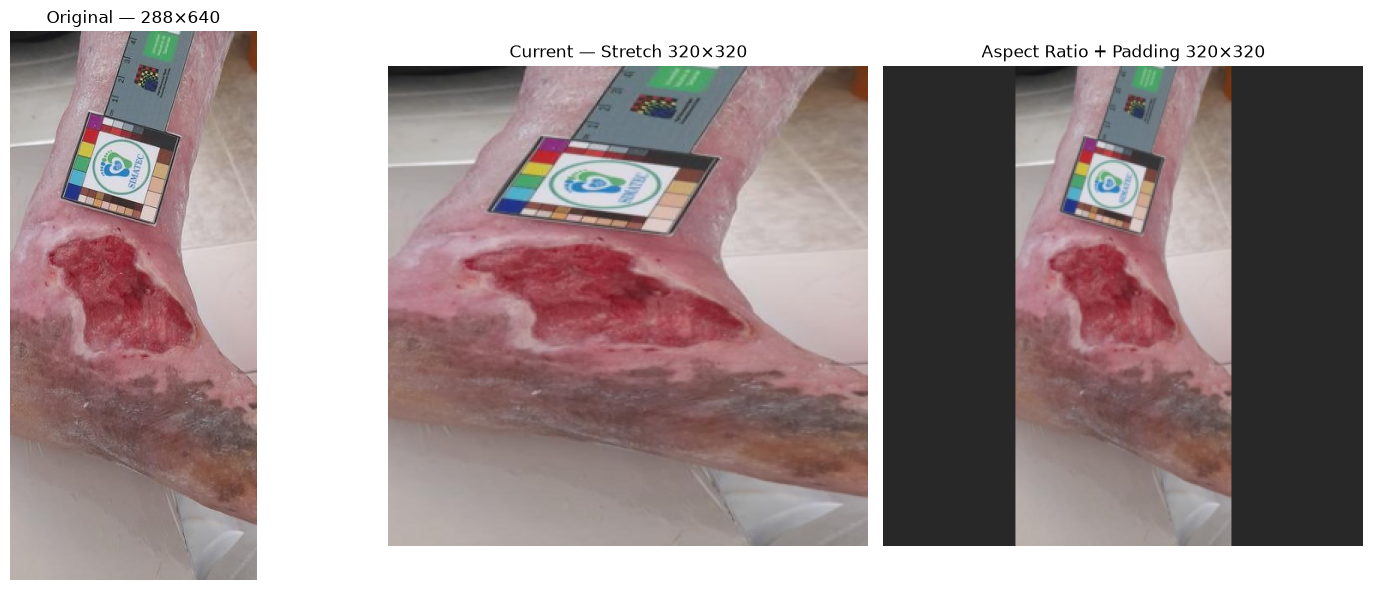

Original: (288, 640)
Stretch: (320, 320)
Letterbox: (320, 320)


In [19]:
from PIL import Image, ImageOps

# Ambil gambar asli Image 16
with Image.open(image_paths[0]) as im:
    original = im.convert("RGB")

# Metode 1: resize saat ini (stretch)
stretched_image, _ = val_dataset[16]

stretched = (
    stretched_image.permute(1, 2, 0).numpy()
)

# Metode 2: pertahankan aspect ratio + padding
letterboxed = ImageOps.pad(
    original,
    size=(320, 320),
    method=Image.Resampling.BILINEAR,
    color=(40, 40, 40)
)

# Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

axes[0].imshow(original)
axes[0].set_title("Original — 288×640")

axes[1].imshow(stretched)
axes[1].set_title("Current — Stretch 320×320")

axes[2].imshow(letterboxed)
axes[2].set_title("Aspect Ratio + Padding 320×320")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

print("Original:", original.size)
print("Stretch:", stretched.shape[:2])
print("Letterbox:", letterboxed.size)

In [20]:
from collections import Counter
from PIL import Image
import pandas as pd

records = []

for split in ["train", "val"]:

    split_path = DATA_ROOT / f"{split}.txt"

    lines = [
        line.strip()
        for line in split_path.read_text().splitlines()
        if line.strip()
    ]

    for line in lines:

        image_name, mask_name = line.split()[:2]

        image_path = DATA_ROOT / image_name
        mask_path = DATA_ROOT / mask_name

        with Image.open(image_path) as image:
            width, height = image.size

        with Image.open(mask_path) as mask:
            mask_width, mask_height = mask.size

        records.append({
            "split": split,
            "image": image_name,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "distortion_ratio": max(
                width / height,
                height / width
            ),
            "mask_match": (
                width == mask_width
                and height == mask_height
            )
        })

df_resolution = pd.DataFrame(records)

print("=== LUTSEG RESOLUTION AUDIT ===")

print("Total images:", len(df_resolution))

print("\nOrientation:")
print("Portrait:", (df_resolution.width < df_resolution.height).sum())
print("Landscape:", (df_resolution.width > df_resolution.height).sum())
print("Square:", (df_resolution.width == df_resolution.height).sum())

print("\nMost common resolutions:")
print(
    df_resolution.groupby(["width", "height"])
    .size()
    .sort_values(ascending=False)
    .head(10)
)

print("\nAspect ratio:")
print(df_resolution["aspect_ratio"].describe().round(3))

print("\nImages with aspect ratio distortion > 2x:")
print((df_resolution["distortion_ratio"] > 2).sum())

print("\nImage-mask dimensions matched:")
print(df_resolution["mask_match"].all())

=== LUTSEG RESOLUTION AUDIT ===
Total images: 141

Orientation:
Portrait: 141
Landscape: 0
Square: 0

Most common resolutions:
width  height
640    853       59
3120   4160      34
640    1422      13
480    640        9
288    640        9
640    852        4
720    1600       2
1200   1600       2
640    808        1
560    720        1
dtype: int64

Aspect ratio:
count    141.000
mean       0.699
std        0.115
min        0.450
25%        0.750
50%        0.750
75%        0.750
max        0.830
Name: aspect_ratio, dtype: float64

Images with aspect ratio distortion > 2x:
24

Image-mask dimensions matched:
True


Original size: (288, 640)
Resized content: (230, 512)
Canvas size: (384, 512)
Mask labels: [0 1 2 3]
Padding pixels: 78848


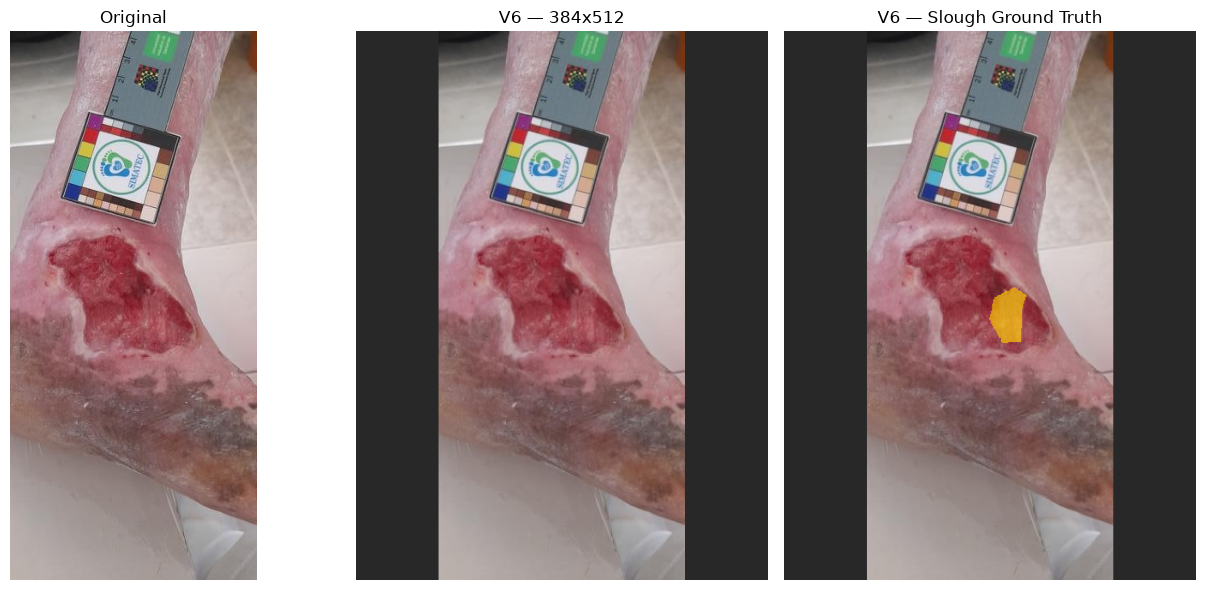

In [21]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# 1. Target resolusi V6
TARGET_W = 384
TARGET_H = 512

# 2. Baca gambar dan mask asli Image 16
with Image.open(image_paths[0]) as im:
    original_img = im.convert("RGB")

with Image.open(mask_paths[0]) as m:
    original_mask = m.convert("L")

# 3. Hitung skala agar aspect ratio tetap
w, h = original_img.size

scale = min(TARGET_W / w, TARGET_H / h)

new_w = round(w * scale)
new_h = round(h * scale)

# 4. Resize gambar dan mask
resized_img = original_img.resize(
    (new_w, new_h),
    Image.Resampling.BILINEAR
)

resized_mask = original_mask.resize(
    (new_w, new_h),
    Image.Resampling.NEAREST
)

# 5. Buat kanvas untuk padding
img_canvas = Image.new(
    "RGB", (TARGET_W, TARGET_H), (40, 40, 40)
)

mask_canvas = Image.new(
    "L", (TARGET_W, TARGET_H), 255
)

# 6. Tempatkan di tengah
left = (TARGET_W - new_w) // 2
top = (TARGET_H - new_h) // 2

img_canvas.paste(resized_img, (left, top))
mask_canvas.paste(resized_mask, (left, top))

# 7. Verifikasi mask
mask_np = np.array(mask_canvas)

print("Original size:", original_img.size)
print("Resized content:", (new_w, new_h))
print("Canvas size:", img_canvas.size)
print(
    "Mask labels:",
    np.unique(mask_np[mask_np != 255])
)
print("Padding pixels:", (mask_np == 255).sum())

# 8. Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(13, 6))

axes[0].imshow(original_img)
axes[0].set_title("Original")

axes[1].imshow(img_canvas)
axes[1].set_title("V6 — 384x512")

axes[2].imshow(img_canvas)

overlay = np.zeros((*mask_np.shape, 4))
overlay[mask_np == 2] = [1, 0.8, 0, 0.65]

axes[2].imshow(overlay)
axes[2].set_title("V6 — Slough Ground Truth")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [22]:
# === STEP 21: EVALUATOR AUDIT ===

import inspect

print("=== EVALUATE MODEL ===")
print(inspect.getsource(evaluate_model))

print("\n=== CALCULATE METRICS ===")
print(inspect.getsource(calculate_metrics))

=== EVALUATE MODEL ===
def evaluate_model(model, val_loader, device):
    """Evaluate all validation images."""

    model.eval()

    cm = torch.zeros(
        (NUM_CLASSES, NUM_CLASSES),
        dtype=torch.long
    )

    mean = torch.tensor(MEAN, device=device).view(1, 3, 1, 1)
    std = torch.tensor(STD, device=device).view(1, 3, 1, 1)

    with torch.inference_mode():
        for images, masks in val_loader:

            # Same preprocessing as Google Colab
            images = images.to(device)
            images = (images - mean) / std

            logits = model(images)
            predictions = logits.argmax(dim=1).cpu()

            masks = masks.cpu()

            # Ignore unlabeled pixels
            valid = (
                (masks != 255)
                & (masks >= 0)
                & (masks < NUM_CLASSES)
            )

            indices = (
                masks[valid] * NUM_CLASSES
                + predictions[valid]
            )

            cm += torch.bincoun

In [23]:
# === STEP 22: CONFUSION MATRIX AUDIT ===

import inspect

source = inspect.getsource(evaluate_model)
lines = source.splitlines()

# Cari bagian setelah mask dipindahkan ke CPU
start = next(
    i for i, line in enumerate(lines)
    if "masks = masks.cpu()" in line
)

print("=== CONFUSION MATRIX IMPLEMENTATION ===")

for i in range(start, len(lines)):
    print(f"{i+1:02d} | {lines[i]}")

=== CONFUSION MATRIX IMPLEMENTATION ===
24 |             masks = masks.cpu()
25 | 
26 |             # Ignore unlabeled pixels
27 |             valid = (
28 |                 (masks != 255)
29 |                 & (masks >= 0)
30 |                 & (masks < NUM_CLASSES)
31 |             )
32 | 
33 |             indices = (
34 |                 masks[valid] * NUM_CLASSES
35 |                 + predictions[valid]
36 |             )
37 | 
38 |             cm += torch.bincount(
39 |                 indices.long(),
40 |                 minlength=NUM_CLASSES ** 2
41 |             ).reshape(NUM_CLASSES, NUM_CLASSES)
42 | 
43 |     return cm


In [ ]:
from torch.utils.data import Dataset
from PIL import Image
import numpy as np
import torch

class AspectRatioWoundDataset(Dataset):

    def __init__(
        self,
        root_dir,
        split_file,
        output_size=(384, 512),
        transform=None
    ):
        self.root_dir = Path(root_dir)
        self.output_size = output_size  # (width, height)
        self.transform = transform

        lines = (self.root_dir / split_file).read_text().splitlines()

        self.pairs = [
            line.split()[:2]
            for line in lines
            if line.strip()
        ]

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):

        image_name, mask_name = self.pairs[idx]

        with Image.open(self.root_dir / image_name) as im:
            image = im.convert("RGB")

        with Image.open(self.root_dir / mask_name) as m:
            mask = m.convert("L")

        if image.size != mask.size:
            raise ValueError("Image and mask size mismatch")

        target_w, target_h = self.output_size
        w, h = image.size

        # Resize tanpa mengubah aspect ratio
        scale = min(target_w / w, target_h / h)
        new_w = max(1, round(w * scale))
        new_h = max(1, round(h * scale))

        image = image.resize(
            (new_w, new_h),
            Image.Resampling.BILINEAR
        )

        mask = mask.resize(
            (new_w, new_h),
            Image.Resampling.NEAREST
        )

        # Augmentasi hanya pada gambar sebelum padding
        if self.transform is not None:
            image = self.transform(image)

        # Padding gambar dan mask
        image_canvas = Image.new(
            "RGB", self.output_size, (40, 40, 40)
        )

        mask_canvas = Image.new(
            "L", self.output_size, 255
        )

        left = (target_w - new_w) // 2
        top = (target_h - new_h) // 2

        image_canvas.paste(image, (left, top))
        mask_canvas.paste(mask, (left, top))

        # Konversi ke tensor
        image_tensor = torch.from_numpy(
            np.array(image_canvas)
        ).permute(2, 0, 1).float() / 255.0

        mask_tensor = torch.from_numpy(
            np.array(mask_canvas, dtype=np.int64)
        )

        if self.transform is not None:
            image_tensor = self.transform(image_tensor)

        return image_tensor, mask_tensor


# Uji dataset validasi tanpa augmentasi
val_dataset_v6 = AspectRatioWoundDataset(
    root_dir=DATA_ROOT,
    split_file="val.txt",
    output_size=(384, 512)
)

image_v6, mask_v6 = val_dataset_v6[16]

print("=== V6 DATASET CHECK ===")
print("Total images:", len(val_dataset_v6))
print("Image shape:", image_v6.shape)
print("Mask shape:", mask_v6.shape)
print("Image range:", image_v6.min().item(), image_v6.max().item())
print("Mask labels:", torch.unique(mask_v6).tolist())
print("Padding pixels:", (mask_v6 == 255).sum().item())

=== V6 DATASET CHECK ===
Total images: 30
Image shape: torch.Size([3, 512, 384])
Mask shape: torch.Size([512, 384])
Image range: 0.05098039284348488 0.9803921580314636
Mask labels: [0, 1, 2, 3, 255]
Padding pixels: 78848


=== V6 VALIDATION INTEGRITY ===
Total images: 30
Invalid samples: []
Dataset valid: True


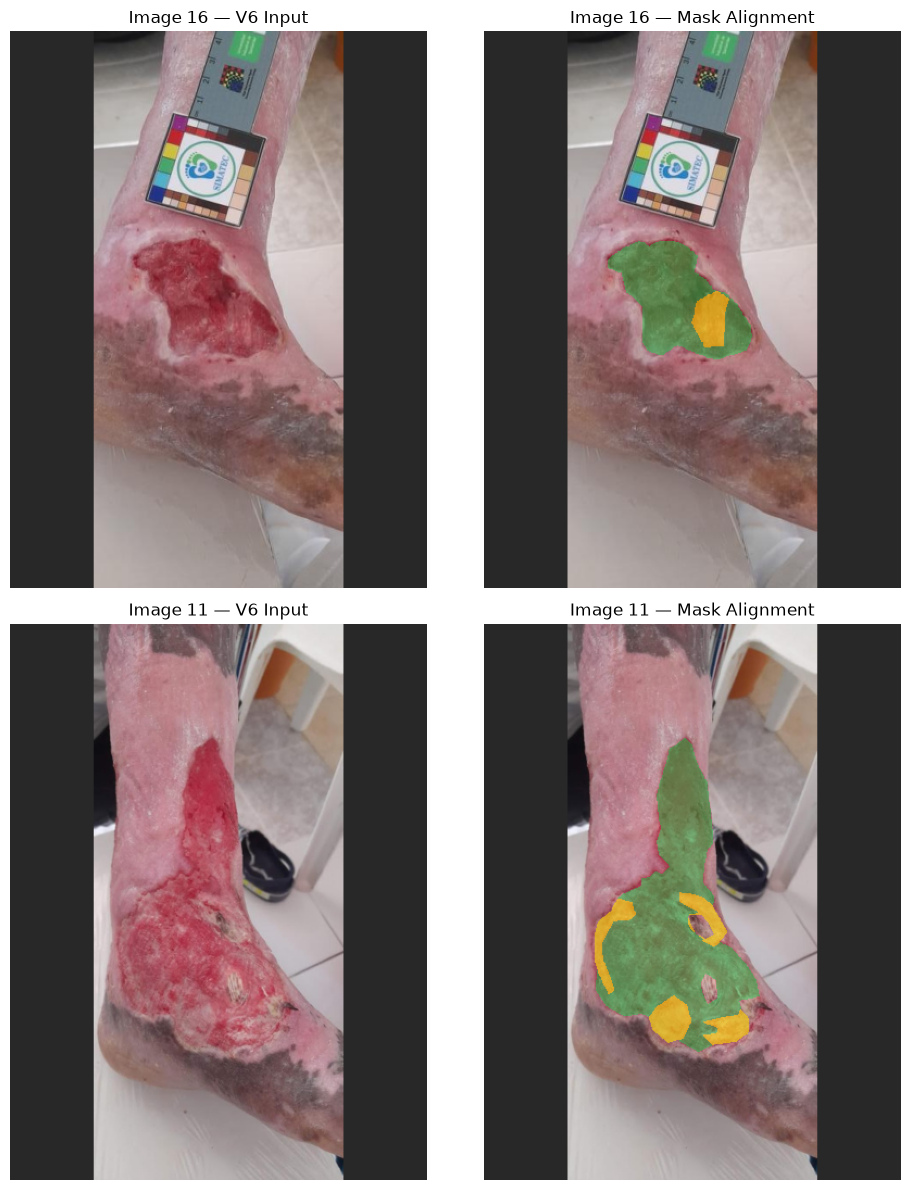

In [25]:
# === STEP 24: DATASET INTEGRITY CHECK ===

import numpy as np
import matplotlib.pyplot as plt

valid_labels = {0, 1, 2, 3, 4, 5, 255}
invalid_samples = []

# 1. Periksa seluruh validation dataset
for idx in range(len(val_dataset_v6)):

    image, mask = val_dataset_v6[idx]

    labels = set(torch.unique(mask).tolist())

    if not labels.issubset(valid_labels):
        invalid_samples.append({
            "index": idx,
            "labels": labels
        })

    if image.shape != (3, 512, 384):
        invalid_samples.append({
            "index": idx,
            "error": "Invalid image shape"
        })

    if mask.shape != (512, 384):
        invalid_samples.append({
            "index": idx,
            "error": "Invalid mask shape"
        })

print("=== V6 VALIDATION INTEGRITY ===")
print("Total images:", len(val_dataset_v6))
print("Invalid samples:", invalid_samples)
print("Dataset valid:", len(invalid_samples) == 0)


# 2. Visualisasi alignment dua gambar
sample_indices = [16, 11]

fig, axes = plt.subplots(2, 2, figsize=(10, 12))

for row, idx in enumerate(sample_indices):

    image, mask = val_dataset_v6[idx]

    img_np = image.permute(1, 2, 0).numpy()
    mask_np = mask.numpy()

    # Overlay untuk dua jenis jaringan
    overlay = np.zeros((*mask_np.shape, 4))

    # Kuning = Slough
    overlay[mask_np == 2] = [1, 0.85, 0, 0.6]

    # Hijau = Granulation
    overlay[mask_np == 3] = [0, 0.9, 0.3, 0.4]

    axes[row, 0].imshow(img_np)
    axes[row, 0].set_title(f"Image {idx} — V6 Input")

    axes[row, 1].imshow(img_np)
    axes[row, 1].imshow(overlay)
    axes[row, 1].set_title(f"Image {idx} — Mask Alignment")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

In [26]:
mask = mask.resize(
    (new_w, new_h),
    Image.Resampling.NEAREST
)

/var/folders/0d/28ch67w178d_7jvkjx3q14kc0000gn/T/ipykernel_22020/4168455948.py:1: UserWarning: non-inplace resize is deprecated
  mask = mask.resize(


RuntimeError: requested resize to (230, 512)x0 (() elements in total), but the given tensor has a size of 512x384 (196608 elements). autograd's resize can only change the shape of a given tensor, while preserving the number of elements. 